Homework 9, problem 3, part c

In [1]:
# libraries and parameters
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.optimize import brentq

Q = np.array([
    [-2,  2,  0,  0],
    [ 1, -3,  2,  0],
    [ 0,  2, -4,  2],
    [ 0,  0,  3, -3]
], dtype=float)

x0 = np.array([1, 0, 0, 0], dtype=float)
pi = np.array([3, 6, 6, 4], dtype=float) / 19

In [2]:
# eigenvalues
eigenvalues = np.linalg.eigvals(Q)
print("Eigenvalues:", np.sort(eigenvalues))

# 2nd eigenvalue
lambda2 = max(e.real for e in eigenvalues if abs(e) > 1e-8)
print("second eigenvalue:", lambda2)

Eigenvalues: [-6.77845712e+00 -3.71083145e+00 -1.51071143e+00 -2.34135828e-17]
second eigenvalue: -1.5107114281899212


In [3]:
# probability distribution at time t
def probabilities(t):
    return x0 @ expm(t * Q)

# total variation distance
def TV(t):
    x = probabilities(t)
    return 0.5 * np.sum(np.abs(x - pi))

In [4]:
times = np.linspace(0, 8, 400)
X = np.array([probabilities(t) for t in times])
tv_values = np.array([TV(t) for t in times])

t_actual = brentq(lambda t: TV(t) - 0.01, 0, 8) # time when tv = 0.01

t_estimate = np.log(100) / abs(lambda2) # theoretical estimate using the second eigenvalue

print("time when TV = 0.01:", t_actual)
print("theoretical estimate:", t_estimate)

time when TV = 0.01: 2.897990636021128
theoretical estimate: 3.0483453689801214


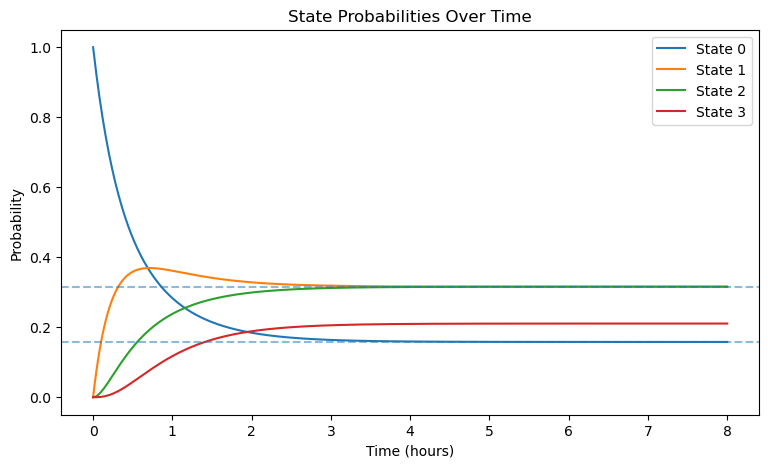

In [5]:
# plotting state probabilities
plt.figure(figsize=(9, 5))

for i in range(4):
    plt.plot(times, X[:, i], label=f"State {i}")

plt.axhline(pi[0], linestyle="--", alpha=0.5)
plt.axhline(pi[1], linestyle="--", alpha=0.5)

plt.xlabel("Time (hours)")
plt.ylabel("Probability")
plt.title("State Probabilities Over Time")
plt.legend()
plt.show()

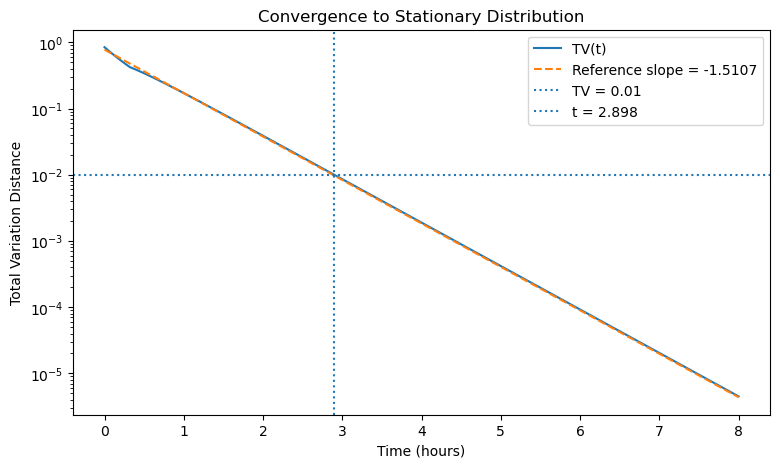

In [7]:
# plotting total variation distance
plt.figure(figsize=(9, 5))

plt.semilogy(times, tv_values, label="TV(t)")

reference = TV(1) * np.exp(-abs(lambda2) * (times - 1)) # slope -|lambda2|

plt.semilogy(
    times, reference, "--",
    label=f"Reference slope = -{abs(lambda2):.4f}"
)

plt.axhline(0.01, linestyle=":", label="TV = 0.01")
plt.axvline(t_actual, linestyle=":", label=f"t = {t_actual:.3f}")

plt.xlabel("Time (hours)")
plt.ylabel("Total Variation Distance")
plt.title("Convergence to Stationary Distribution")
plt.legend()
plt.show()